# Ethanol Stress Response in Kveik vs Ale Yeast (RNA-seq)

Kveik are traditional Norwegian yeast strains used in brewing. They are known to tolerate stress like high temperature and ethanol much better than normal brewing yeast, which makes them interesting for industrial fermentation.

In this project I compare how 3 kveik strains and 1 ale strain respond to ethanol stress at the gene expression level.

**Questions:**
1. Which genes respond to ethanol in all strains?
2. Do kveik strains respond to ethanol differently from the ale strain?
3. Are stress genes like HSP12 and CTT1 already higher in kveik before stress (as reported in the original study)?

**Dataset:** GEO GSE331206
- Ale strain: UNY003
- Kveik strains: NCYC3996, NCYC3997, NCYC4285
- Conditions: control (30°C) and ethanol, 3 replicates each

**Note:** the dataset only has normalized counts (no raw counts), so I used **limma** instead of DESeq2.

## 1. Install and load packages
This takes some time on Colab (around 10 minutes).

In [1]:
# use pre-built packages for this version of Ubuntu, so the installation is faster
ubuntu <- system("lsb_release -cs", intern = TRUE)
options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", ubuntu, "/latest")))
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))

install.packages(c("ggplot2", "ggrepel", "pheatmap", "gprofiler2", "BiocManager"))
BiocManager::install("limma", update = FALSE, ask = FALSE)

# check that everything was installed
c("limma", "ggplot2", "ggrepel", "pheatmap", "gprofiler2") %in% rownames(installed.packages())

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bitops’, ‘lazyeval’, ‘RCurl’, ‘plotly’, ‘crosstalk’, ‘gridExtra’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://packagemanager.posit.co/cran/__linux__/noble/latest

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'limma'

also installing the dependency ‘statmod’




[1] TRUE TRUE TRUE TRUE TRUE

In [2]:
library(limma)
library(ggplot2)
library(ggrepel)
library(pheatmap)
library(gprofiler2)

## 2. Load the data

In [3]:
url <- "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE331nnn/GSE331206/suppl/GSE331206_norm_counts_Scerevisiae.csv.gz"
download.file(url, "counts.csv.gz")

data <- read.csv("counts.csv.gz")
dim(data)

[1] 5985   40

In [4]:
head(data[, 1:6])

,Gene.stable.ID,RefSeq.DNA.ID,Gene.name,Gene.Synonym,UNY003_30_1,UNY003_30_2
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,YPL071C,NM_001183885.1,,,8.469737,6.582673
2,YLL050C,NM_001181870.1,COF1,cofilin,51.877142,34.229900
3,YMR172W,NM_001182677.1,HOT1,,38.113818,44.762177
4,YOR185C,NM_001183604.1,GSP2,CNR2,110.106587,85.574750
5,YLL032C,NM_001181852.1,,,74.110203,76.359007
6,YBR225W,NM_001178573.1,,,225.506759,235.659695


## 3. Clean the data

Some genes are repeated in more than one row. They have the same ID and the same values, only the synonym column is different. So I keep one row for each gene.

In [5]:
sum(duplicated(data$Gene.stable.ID))

data <- data[!duplicated(data$Gene.stable.ID), ]
dim(data)

[1] 100

[1] 5885   40

In [6]:
# how many genes have no name in the file?
sum(is.na(data$Gene.name) | data$Gene.name == "")

[1] 5566

A lot of genes (including well known ones like HSP12) have no name in this file, so I get the gene names from g:Profiler using the gene IDs.

In [7]:
gene_names <- gconvert(data$Gene.stable.ID, organism = "scerevisiae",
                       target = "ENSG", mthreshold = 1, filter_na = FALSE)

data$Gene.name <- gene_names$name[match(data$Gene.stable.ID, gene_names$input)]

# if a gene still has no name, I use its ID
no_name <- is.na(data$Gene.name) | data$Gene.name %in% c("", "None", "nan")
data$Gene.name[no_name] <- data$Gene.stable.ID[no_name]

# check
data[data$Gene.stable.ID %in% c("YFL014W", "YGR088W"), c("Gene.stable.ID", "Gene.name")]

,Gene.stable.ID,Gene.name
,<chr>,<chr>
2000,YFL014W,HSP12
2388,YGR088W,CTT1


## 4. Prepare the counts and sample information

In [8]:
# the first 4 columns are gene information, the rest are the samples
counts <- data[, 5:ncol(data)]
rownames(counts) <- data$Gene.stable.ID

colnames(counts)

[1] "UNY003_30_1"     "UNY003_30_2"     "UNY003_30_3"     "NCYC3996_30_1"  
 [5] "NCYC3996_30_2"   "NCYC3996_30_3"   "NCYC3997_30_1"   "NCYC3997_30_2"  
 [9] "NCYC3997_30_3"   "NCYC4285_30_1"   "NCYC4285_30_2"   "NCYC4285_30_3"  
[13] "UNY003_37_1"     "UNY003_37_2"     "UNY003_37_3"     "NCYC3996_42_1"  
[17] "NCYC3996_42_2"   "NCYC3996_42_3"   "NCYC3997_42_1"   "NCYC3997_42_2"  
[21] "NCYC3997_42_3"   "NCYC4285_42_1"   "NCYC4285_42_2"   "NCYC4285_42_3"  
[25] "UNY003_EtOH_1"   "UNY003_EtOH_2"   "UNY003_EtOH_3"   "NCYC3996_EtOH_1"
[29] "NCYC3996_EtOH_2" "NCYC3996_EtOH_3" "NCYC3997_EtOH_1" "NCYC3997_EtOH_2"
[33] "NCYC3997_EtOH_3" "NCYC4285_EtOH_1" "NCYC4285_EtOH_2" "NCYC4285_EtOH_3"

The sample names look like `UNY003_30_1` (strain_condition_replicate), so I split them to get the strain and the condition.

In [9]:
samples <- colnames(counts)
info <- do.call(rbind, strsplit(samples, "_"))

metadata <- data.frame(sample = samples,
                       strain = info[, 1],
                       condition = info[, 2])
head(metadata)

,sample,strain,condition
,<chr>,<chr>,<chr>
1,UNY003_30_1,UNY003,30
2,UNY003_30_2,UNY003,30
3,UNY003_30_3,UNY003,30
4,NCYC3996_30_1,NCYC3996,30
5,NCYC3996_30_2,NCYC3996,30
6,NCYC3996_30_3,NCYC3996,30


I only use the control (30°C) and ethanol samples in this project.

In [10]:
metadata <- metadata[metadata$condition %in% c("30", "EtOH"), ]
metadata$condition <- ifelse(metadata$condition == "30", "Control", "Ethanol")

counts <- counts[, metadata$sample]

table(metadata$strain, metadata$condition)

          
           Control Ethanol
  NCYC3996       3       3
  NCYC3997       3       3
  NCYC4285       3       3
  UNY003         3       3

## 5. Filter and log transform

I remove genes with very low expression (less than 10 counts in at least 3 samples), then take log2.

In [11]:
keep <- rowSums(counts >= 10) >= 3
counts <- counts[keep, ]

log_counts <- as.matrix(log2(counts + 1))
nrow(log_counts)

[1] 5837

## 6. PCA

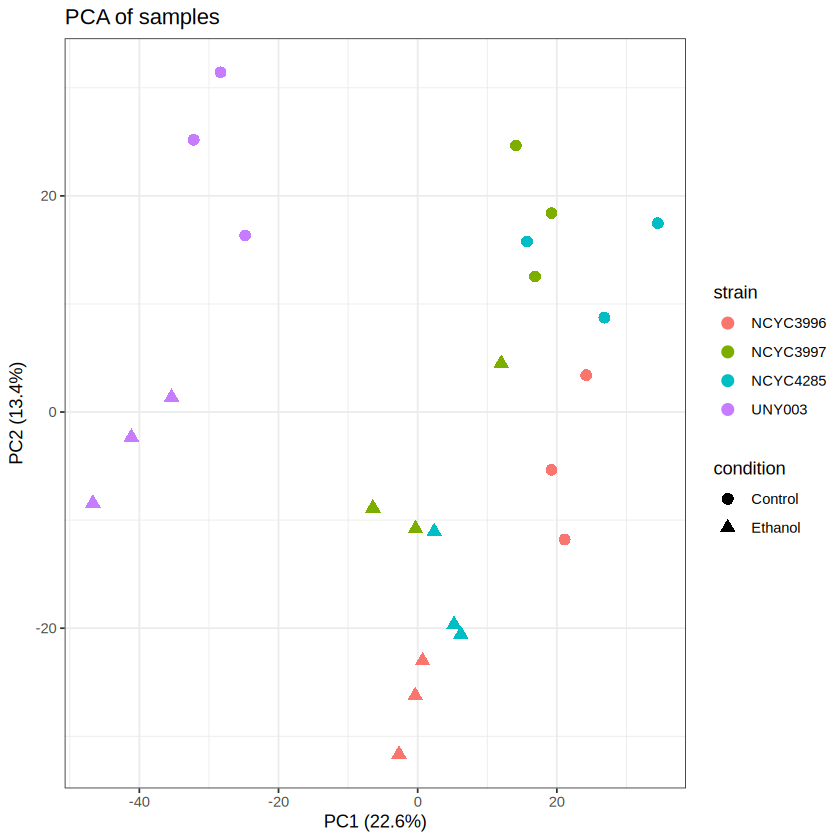

In [12]:
top500 <- order(apply(log_counts, 1, var), decreasing = TRUE)[1:500]
pca <- prcomp(t(log_counts[top500, ]))

pca_df <- data.frame(pca$x[, 1:2], metadata)
percent <- round(summary(pca)$importance[2, 1:2] * 100, 1)

ggplot(pca_df, aes(PC1, PC2, color = strain, shape = condition)) +
  geom_point(size = 3) +
  labs(x = paste0("PC1 (", percent[1], "%)"),
       y = paste0("PC2 (", percent[2], "%)"),
       title = "PCA of samples") +
  theme_bw()

**Observation:** PC1 (22.6%) separates the ale strain UNY003 from the three kveik strains, and PC2 (13.4%) separates control from ethanol samples in all strains. So the biggest difference in the data is the type of yeast, and the second is the ethanol treatment. The replicates of each group are close to each other.

## 7. Differential expression with limma

I make one group for each strain + condition, then compare:
- ethanol vs control in each strain
- the ethanol response of kveik (average of the 3 strains) vs the ethanol response of the ale strain

In [13]:
group <- factor(paste(metadata$strain, metadata$condition, sep = "_"))

design <- model.matrix(~ 0 + group)
colnames(design) <- levels(group)
colnames(design)

[1] "NCYC3996_Control" "NCYC3996_Ethanol" "NCYC3997_Control" "NCYC3997_Ethanol"
[5] "NCYC4285_Control" "NCYC4285_Ethanol" "UNY003_Control"   "UNY003_Ethanol"

In [14]:
contrasts <- makeContrasts(
  UNY003   = UNY003_Ethanol - UNY003_Control,
  NCYC3996 = NCYC3996_Ethanol - NCYC3996_Control,
  NCYC3997 = NCYC3997_Ethanol - NCYC3997_Control,
  NCYC4285 = NCYC4285_Ethanol - NCYC4285_Control,
  Kveik_vs_Ale = (NCYC3996_Ethanol - NCYC3996_Control +
                  NCYC3997_Ethanol - NCYC3997_Control +
                  NCYC4285_Ethanol - NCYC4285_Control) / 3 -
                 (UNY003_Ethanol - UNY003_Control),
  All_strains = (UNY003_Ethanol - UNY003_Control +
                 NCYC3996_Ethanol - NCYC3996_Control +
                 NCYC3997_Ethanol - NCYC3997_Control +
                 NCYC4285_Ethanol - NCYC4285_Control) / 4,
  levels = design)

fit <- lmFit(log_counts, design)
fit2 <- contrasts.fit(fit, contrasts)
fit2 <- eBayes(fit2, trend = TRUE)

Number of significant genes in each comparison (adjusted p-value < 0.05 and |log2FC| > 1):

In [15]:
de_table <- decideTests(fit2, lfc = 1)
summary(de_table)

       UNY003 NCYC3996 NCYC3997 NCYC4285 Kveik_vs_Ale All_strains
Down      200      265      229      480           42         331
NotSig   5394     5221     5499     5065         5773        5241
Up        243      351      109      292           22         265

## 8. Core ethanol response

Genes that go up with ethanol in all 4 strains.

In [16]:
core_up <- rownames(de_table)[rowSums(de_table[, 1:4] == 1) == 4]
core_down <- rownames(de_table)[rowSums(de_table[, 1:4] == -1) == 4]

length(core_up)
length(core_down)

[1] 37

[1] 27

In [17]:
# names of the core up genes
data$Gene.name[match(core_up, data$Gene.stable.ID)]

[1] "RPS14A"    "HSP31"     "SOM1"      "RPL17A"    "YAL065C"   "YBL039W-B"
 [7] "IPP1"      "YCL057C-A" "PTP1"      "CPR1"      "HMF1"      "BMH1"     
[13] "ACT1"      "DUG1"      "RCK1"      "PAC10"     "SCW4"      "DED81"    
[19] "DYS1"      "PRY1"      "RPE1"      "SNA3"      "OPI3"      "RSM7"     
[25] "YKL018C-A" "BUD20"     "AHP1"      "PUN1"      "YMR090W"   "POR1"     
[31] "YNL208W"   "RPS15"     "VMA4"      "EGD1"      "ALD6"      "RPL5"     
[37] "DPM1"

## 9. Kveik vs ale: difference in ethanol response

In [18]:
res <- topTable(fit2, coef = "Kveik_vs_Ale", number = Inf)
res$gene <- data$Gene.name[match(rownames(res), data$Gene.stable.ID)]

head(res[, c("gene", "logFC", "adj.P.Val")], 15)

,gene,logFC,adj.P.Val
,<chr>,<dbl>,<dbl>
YNCP0022W,YNCP0022W,8.120416,0.0003405820
YOL113W,SKM1,-1.776102,0.0009797333
YDR233C,RTN1,-1.909426,0.0009797333
YHL024W,RIM4,-2.588528,0.0014868163
YDL125C,HNT1,-1.238205,0.0014868163
YNCN0005C,YNCN0005C,1.283796,0.0014868163
YOL154W,ZPS1,5.013846,0.0014868163
YPR118W,MRI1,-2.060890,0.0014868163
YMR145C,NDE1,-2.004792,0.0017773479


In [19]:
write.csv(res, "kveik_vs_ale_results.csv")

### Volcano plot


  Not significant   Stronger in ale Stronger in kveik 
             5773                42                22 

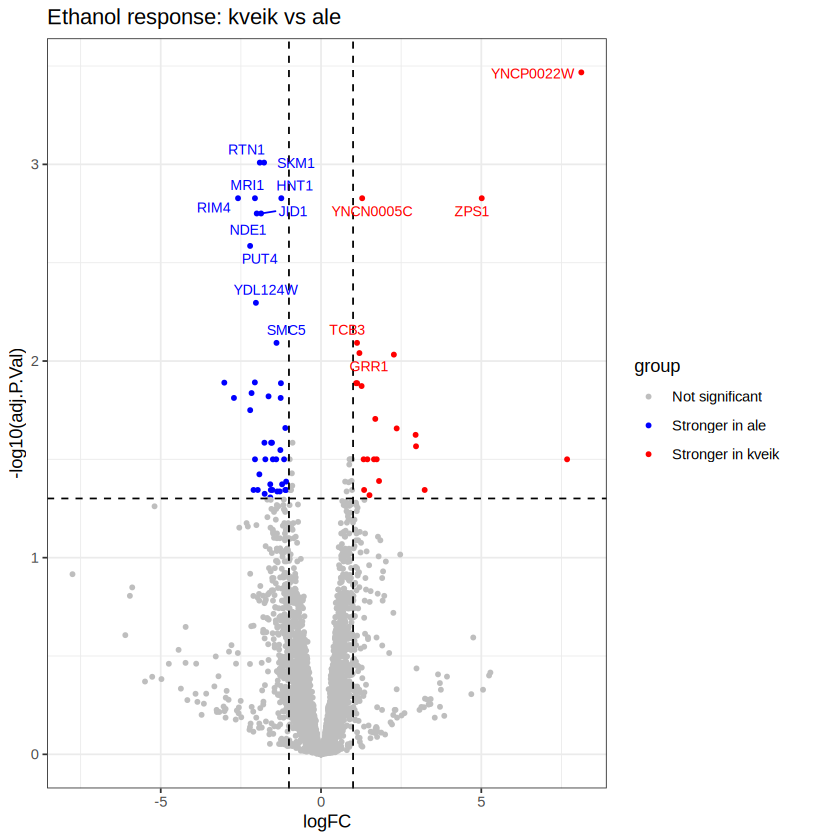

In [20]:
res$group <- "Not significant"
res$group[res$adj.P.Val < 0.05 & res$logFC > 1] <- "Stronger in kveik"
res$group[res$adj.P.Val < 0.05 & res$logFC < -1] <- "Stronger in ale"
table(res$group)

top_genes <- head(res[res$group != "Not significant", ], 15)

ggplot(res, aes(logFC, -log10(adj.P.Val), color = group)) +
  geom_point(size = 1) +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed") +
  geom_vline(xintercept = c(-1, 1), linetype = "dashed") +
  geom_text_repel(data = top_genes, aes(label = gene), size = 3, show.legend = FALSE) +
  scale_color_manual(values = c("Stronger in kveik" = "red",
                                "Stronger in ale" = "blue",
                                "Not significant" = "grey")) +
  labs(title = "Ethanol response: kveik vs ale") +
  theme_bw()

### Heatmap of the top 40 genes

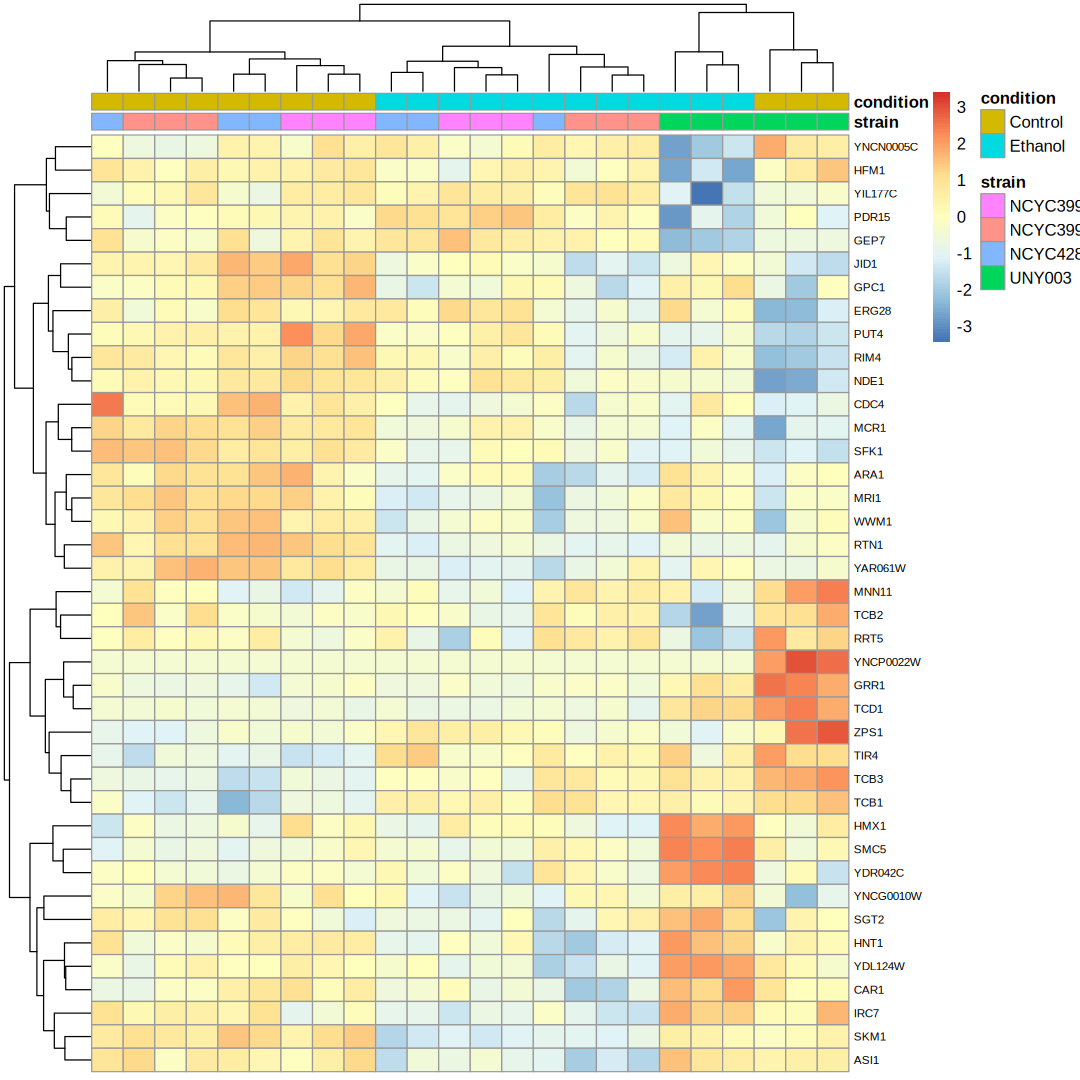

In [21]:
options(repr.plot.width = 9, repr.plot.height = 9)

top40 <- rownames(res)[1:40]
heat_data <- log_counts[top40, ]
rownames(heat_data) <- res[top40, "gene"]

annotation <- data.frame(strain = metadata$strain,
                         condition = metadata$condition,
                         row.names = metadata$sample)

pheatmap(heat_data, scale = "row", annotation_col = annotation,
         show_colnames = FALSE, fontsize_row = 7)

## 10. HSP12 and CTT1

The original study found that these two stress genes are higher in kveik even before stress. Let's check.

Both genes are plotted the same way, so I wrote a small function for it. I use the systematic gene IDs: HSP12 is YFL014W and CTT1 is YGR088W.

In [22]:
options(repr.plot.width = 7, repr.plot.height = 5)

plot_gene <- function(gene_id, gene_name) {
  metadata$expression <- log_counts[gene_id, metadata$sample]

  ggplot(metadata, aes(strain, expression, fill = condition)) +
    geom_boxplot() +
    labs(y = "log2 expression", title = paste0(gene_name, " (", gene_id, ")")) +
    theme_bw()
}

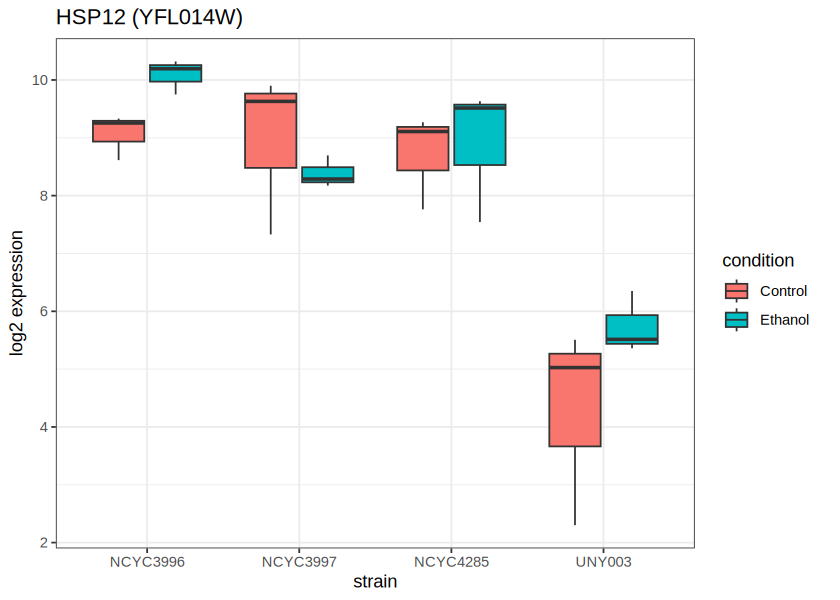

In [23]:
plot_gene("YFL014W", "HSP12")

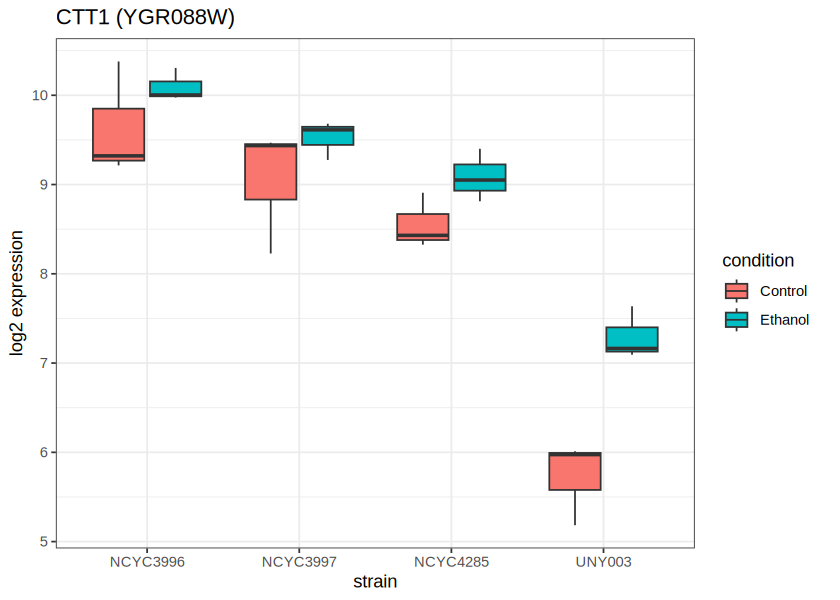

In [24]:
plot_gene("YGR088W", "CTT1")

**Observation:** In the control condition, HSP12 and CTT1 are clearly higher in all three kveik strains than in the ale strain. From the plots, the difference is about 4 log2 units for HSP12 (around 16-fold) and about 3 log2 units for CTT1 (around 8-fold). These values are estimated from the plots, not from a statistical test. This suggests that these stress genes are already active in kveik before any stress, which agrees with the original study.

With ethanol, CTT1 goes up in all four strains, with the biggest increase in the ale strain. HSP12 goes up in UNY003 and NCYC3996, slightly in NCYC4285, and goes down in NCYC3997. Even after ethanol, the ale strain still has lower levels of both genes than the kveik strains.

## 11. GO enrichment

I use **g:Profiler** (gprofiler2 package) for GO enrichment, with all genes that passed filtering as the background. I run it for two gene lists, so I wrote two small functions: one for the enrichment and one for the plot.

In [25]:
run_go <- function(gene_list) {
  go <- gost(query = gene_list,
             organism = "scerevisiae",
             sources = "GO:BP",
             custom_bg = rownames(log_counts))
  go$result
}

plot_go <- function(go_table, title) {
  if (is.null(go_table)) {
    return("No significant GO terms")
  }
  top <- head(go_table[order(go_table$p_value), ], 15)

  ggplot(top, aes(x = -log10(p_value), y = reorder(term_name, -log10(p_value)))) +
    geom_col(fill = "steelblue") +
    labs(x = "-log10 adjusted p-value", y = "", title = title) +
    theme_bw()
}

### Ethanol response in all strains

The 37 genes that were up in all 4 strains gave no significant GO terms. Requiring a gene to pass the cutoffs in every strain separately is very strict, and the list was a mix of unrelated genes (for example ribosomal proteins and ACT1).

A better way is to use the **average ethanol response of the 4 strains** (the `All_strains` contrast), which uses all 24 samples together.

In [26]:
all_res <- topTable(fit2, coef = "All_strains", number = Inf)

ethanol_up <- rownames(all_res)[all_res$adj.P.Val < 0.05 & all_res$logFC > 1]
ethanol_down <- rownames(all_res)[all_res$adj.P.Val < 0.05 & all_res$logFC < -1]

length(ethanol_up)
length(ethanol_down)

[1] 265

[1] 331

In [27]:
go_up <- run_go(ethanol_up)
head(go_up[, c("term_name", "p_value", "intersection_size")], 10)

Detected custom background input, domain scope is set to 'custom'.



,term_name,p_value,intersection_size
,<chr>,<dbl>,<int>
1,cytoplasmic translation,5.049468e-32,65
2,translation,9.137039e-19,78
3,protein biosynthetic process,9.137039e-19,78
4,ribosome biogenesis,2.831609e-08,55
5,protein metabolic process,1.638709e-06,117
6,ribonucleoprotein complex biogenesis,1.165346e-05,57
7,ribosomal large subunit biogenesis,4.338616e-05,26
8,ribosomal subunit export from nucleus,6.421455e-05,18
9,ribosome localization,8.321640e-05,18


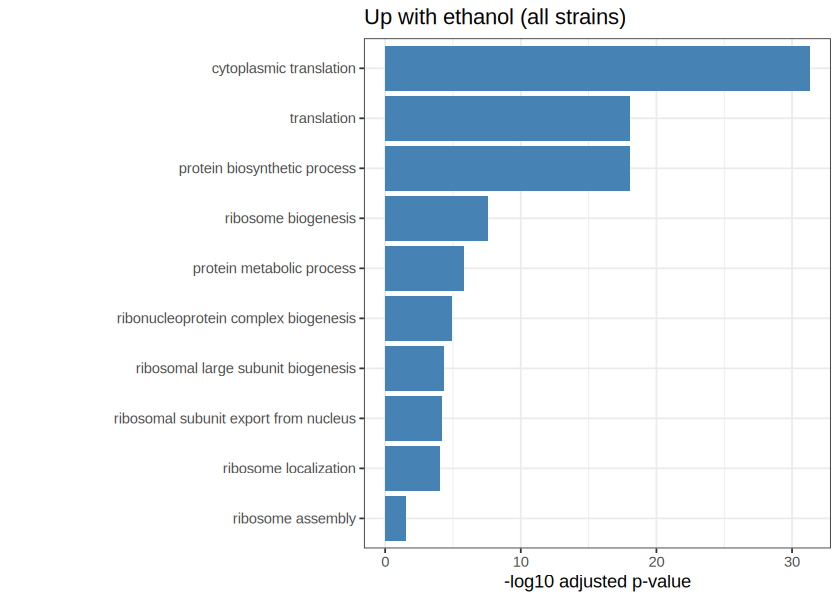

In [28]:
plot_go(go_up, "Up with ethanol (all strains)")

In [29]:
go_down <- run_go(ethanol_down)
head(go_down[, c("term_name", "p_value", "intersection_size")], 10)

Detected custom background input, domain scope is set to 'custom'.

No results to show
Please make sure that the organism is correct or set significant = FALSE



NULL

In [30]:
plot_go(go_down, "Down with ethanol (all strains)")

[1] "No significant GO terms"

**Observation:** 265 genes went up and 331 went down on average across the 4 strains. The upregulated genes were strongly enriched for translation and ribosome biogenesis (for example cytoplasmic translation, padj ≈ 5e-32), while the downregulated genes gave no significant GO terms.

This was unexpected. In the classic yeast stress response, ribosome and translation genes usually go **down** during acute stress, because the cells stop growing. Here they went up. This could be related to how the experiment was done (for example the timing of sampling, the ethanol concentration, or the growth phase of the control and ethanol cultures), and the dataset description doesn't give enough detail to explain it. So I report this result as it is, without drawing a strong biological conclusion from it.

### Genes with a stronger response in kveik

In [31]:
kveik_genes <- rownames(res)[res$group == "Stronger in kveik"]

length(kveik_genes)

go_kveik <- run_go(kveik_genes)
head(go_kveik[, c("term_name", "p_value", "intersection_size")], 10)

[1] 22

Detected custom background input, domain scope is set to 'custom'.



,term_name,p_value,intersection_size
,<chr>,<dbl>,<int>
1,endoplasmic reticulum-plasma membrane tethering,0.02009738,3


If the result above is `NULL`, there are no significant GO terms for this gene list.

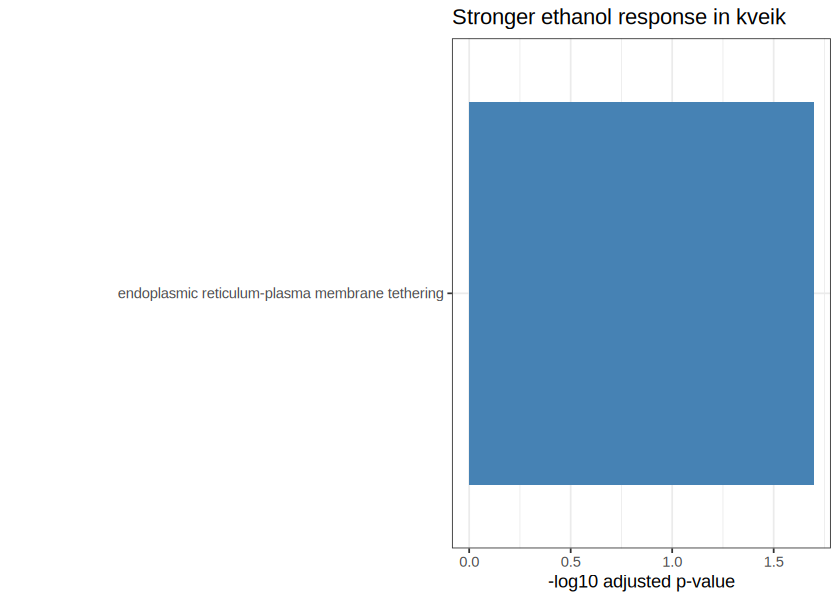

In [32]:
plot_go(go_kveik, "Stronger ethanol response in kveik")

## 12. Conclusion

- The PCA showed that the biggest source of variation is the difference between the kveik strains and the ale strain, followed by the ethanol treatment.
- Each strain changed the expression of several hundred genes after ethanol (from 338 genes in NCYC3997 to 772 in NCYC4285, padj < 0.05 and |log2FC| > 1). But only 37 genes were up and 27 were down in all 4 strains, so a large part of the ethanol response is strain-specific.
- When comparing the ethanol response directly, 22 genes had a stronger response in kveik and 42 in the ale strain. The kveik genes gave only one weak GO term (endoplasmic reticulum–plasma membrane tethering, 3 genes), so the difference in response does not point to one clear pathway.
- On average across all strains, 265 genes went up and 331 went down with ethanol. The upregulated genes were strongly enriched for translation and ribosome biogenesis, which is the opposite of the classic yeast stress response and may reflect the experimental conditions. The downregulated genes had no significant GO terms.
- The clearest result is that the stress genes HSP12 and CTT1 are already much higher in kveik before stress. This suggests that kveik may be "prepared" for stress in advance, which could be part of why they tolerate ethanol better, and it matches the original study.

**Limitations:**
- Only one ale strain was used, so the differences between kveik and ale may be specific to these strains and can't be generalized to all kveik and ale yeasts.
- Only normalized counts were available, so I used limma on log-transformed data instead of a count-based method like DESeq2.
- One ethanol concentration and one time point.
- Some genes with very large fold changes (like YNCP0022W, a non-coding RNA gene) probably have low counts, so they should be interpreted carefully.